In [ ]:
# ==========================================
# Machine Learning - Lecture 5
# Feature Selection
# ==========================================

# 1. Import Libraries

# 2. Load Dataset

# 3. Dataset Information

# 4. Variance Threshold

# 5. Correlation

# 6. Chi-Square

# 7. ANOVA

# 8. Mutual Information

# 9. Wrapper Method (RFE)

# 10. Embedded Method

# 11. Summary

In [4]:
# ==============================
# Data Manipulation
# ==============================
import pandas as pd
import numpy as np

# ==============================
# Data Visualization
# ==============================
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================
# Feature Selection
# ==============================
from sklearn.feature_selection import (
    VarianceThreshold,
    SelectKBest,
    chi2,
    f_classif,
    mutual_info_classif,
    mutual_info_regression,
    RFE
)

# ==============================
# Machine Learning Models
# (For Wrapper & Embedded Methods)
# ==============================
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# ==============================
# Utility
# ==============================
import warnings
warnings.filterwarnings("ignore")

In [5]:
import seaborn as sns

df = sns.load_dataset("titanic")
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [6]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [7]:
df.tail()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [8]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [9]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [10]:
df.duplicated().sum()

np.int64(107)

In [11]:
df.dropna()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
10,1,3,female,4.0,1,1,16.7000,S,Third,child,False,G,Southampton,yes,False
11,1,1,female,58.0,0,0,26.5500,S,First,woman,False,C,Southampton,yes,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
871,1,1,female,47.0,1,1,52.5542,S,First,woman,False,D,Southampton,yes,False
872,0,1,male,33.0,0,0,5.0000,S,First,man,True,B,Southampton,no,True
879,1,1,female,56.0,0,1,83.1583,C,First,woman,False,C,Cherbourg,yes,False
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True


In [12]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [13]:
df.shape

(891, 15)

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [15]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [16]:


df.head()

df.shape

df.columns

df.info()

df.describe()

df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [17]:
correlation_matrix = df.corr(numeric_only=True)

correlation_matrix

,survived,pclass,age,sibsp,parch,fare,adult_male,alone
survived,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307,-0.557080,-0.203367
pclass,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500,0.094035,0.135207
age,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067,0.280328,0.198270
sibsp,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651,-0.253586,-0.584471
parch,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225,-0.349943,-0.583398
fare,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000,-0.182024,-0.271832
adult_male,-0.557080,0.094035,0.280328,-0.253586,-0.349943,-0.182024,1.000000,0.404744
alone,-0.203367,0.135207,0.198270,-0.584471,-0.583398,-0.271832,0.404744,1.000000


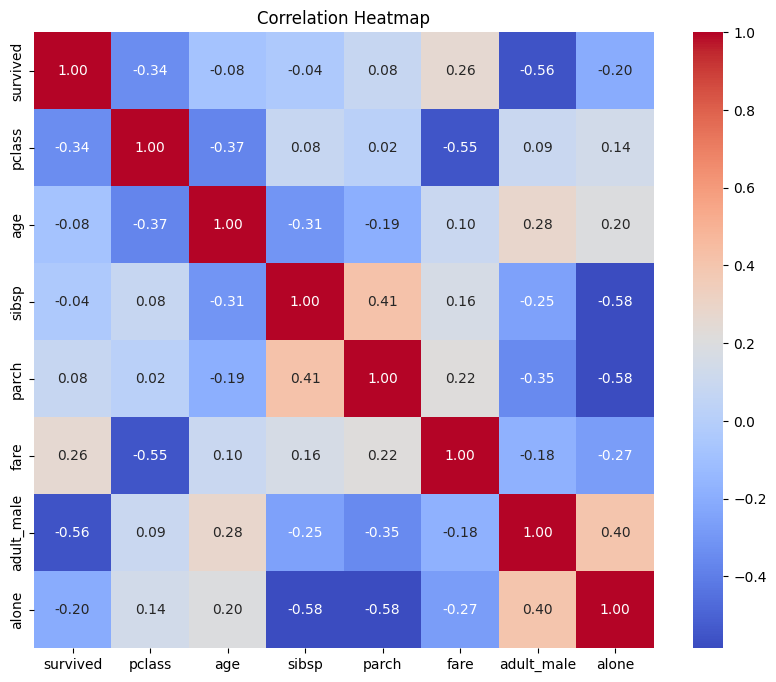

In [18]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

<Axes: >

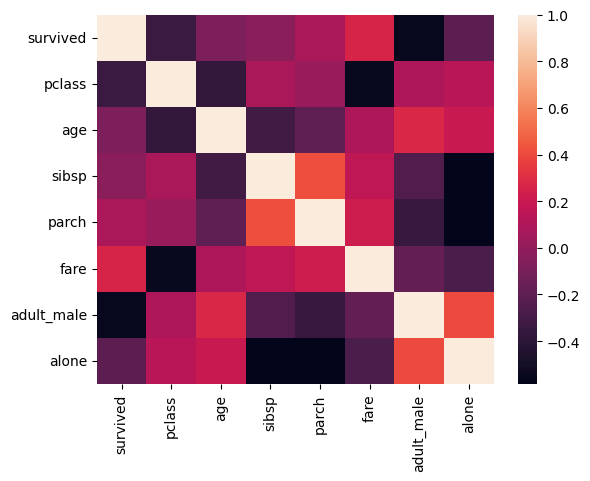

In [19]:
sns.heatmap(df.corr(numeric_only = True))

In [20]:
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

upper_triangle


,survived,pclass,age,sibsp,parch,fare,adult_male,alone
survived,NaN,-0.338481,-0.077221,-0.035322,0.081629,0.257307,-0.557080,-0.203367
pclass,NaN,NaN,-0.369226,0.083081,0.018443,-0.549500,0.094035,0.135207
age,NaN,NaN,NaN,-0.308247,-0.189119,0.096067,0.280328,0.198270
sibsp,NaN,NaN,NaN,NaN,0.414838,0.159651,-0.253586,-0.584471
parch,NaN,NaN,NaN,NaN,NaN,0.216225,-0.349943,-0.583398
fare,NaN,NaN,NaN,NaN,NaN,NaN,-0.182024,-0.271832
adult_male,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.404744
alone,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
import pandas as pd

df = pd.DataFrame({
    "Area": [1000, 1200, 1400, 1600, 1800, 2000, 2200, 2400, 2600, 2800],

    "Area_sqft": [995, 1198, 1395, 1602, 1801, 1998, 2203, 2399, 2601, 2797],

    "Area_meter": [93, 111, 130, 149, 167, 186, 204, 223, 242, 260],

    "Bedrooms": [2, 2, 3, 3, 4, 4, 5, 5, 6, 6],

    "Bathrooms": [1, 2, 2, 2, 3, 3, 4, 4, 5, 5],

    "House_ID": [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],

    "Price": [30, 36, 42, 48, 55, 61, 68, 74, 81, 88]
})

df

,Area,Area_sqft,Area_meter,Bedrooms,Bathrooms,House_ID,Price
0,1000,995,93,2,1,101,30
1,1200,1198,111,2,2,102,36
2,1400,1395,130,3,2,103,42
3,1600,1602,149,3,2,104,48
4,1800,1801,167,4,3,105,55
5,2000,1998,186,4,3,106,61
6,2200,2203,204,5,4,107,68
7,2400,2399,223,5,4,108,74
8,2600,2601,242,6,5,109,81
9,2800,2797,260,6,5,110,88


In [22]:
corrilation_matrix = df.corr(numeric_only = True)

corrilation_matrix

,Area,Area_sqft,Area_meter,Bedrooms,Bathrooms,House_ID,Price
Area,1.000000,0.999991,0.999986,0.984732,0.977513,1.000000,0.999715
Area_sqft,0.999991,1.000000,0.999976,0.984809,0.977644,0.999991,0.999661
Area_meter,0.999986,0.999976,1.000000,0.984718,0.976923,0.999986,0.999661
Bedrooms,0.984732,0.984809,0.984718,1.000000,0.979071,0.984732,0.985609
Bathrooms,0.977513,0.977644,0.976923,0.979071,1.000000,0.977513,0.979527
House_ID,1.000000,0.999991,0.999986,0.984732,0.977513,1.000000,0.999715
Price,0.999715,0.999661,0.999661,0.985609,0.979527,0.999715,1.000000


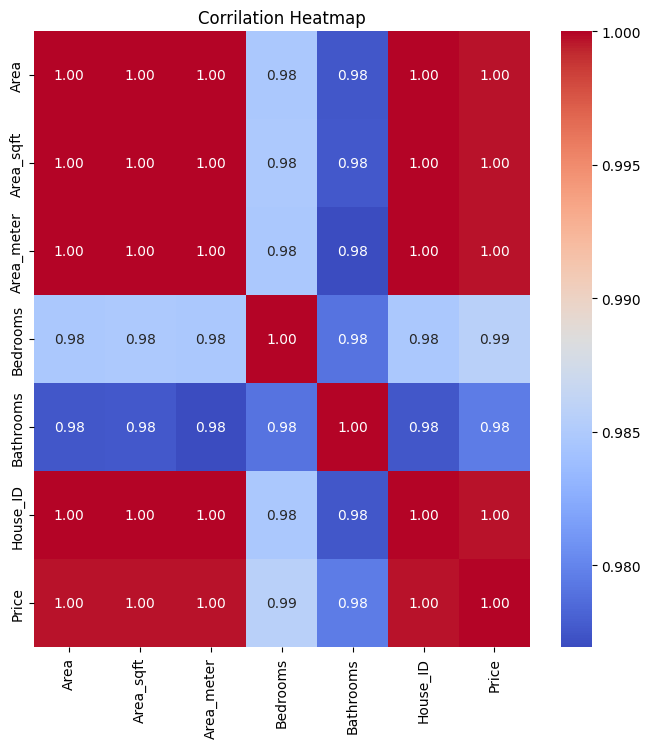

In [23]:
plt.figure(figsize=(8,8))

sns.heatmap(
    corrilation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt = ".2f"
)

plt.title("Corrilation Heatmap")
plt.show()

In [24]:
upper_triangle =  corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape), k=1).astype(bool)
)

upper_triangle


,Area,Area_sqft,Area_meter,Bedrooms,Bathrooms,House_ID,Price
Area,NaN,0.999991,0.999986,0.984732,0.977513,1.000000,0.999715
Area_sqft,NaN,NaN,0.999976,0.984809,0.977644,0.999991,0.999661
Area_meter,NaN,NaN,NaN,0.984718,0.976923,0.999986,0.999661
Bedrooms,NaN,NaN,NaN,NaN,0.979071,0.984732,0.985609
Bathrooms,NaN,NaN,NaN,NaN,NaN,0.977513,0.979527
House_ID,NaN,NaN,NaN,NaN,NaN,NaN,0.999715
Price,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [34]:
a = [1,2,3]

b = a

b[0] = 99

print(a[0])

99


In [25]:
upper_trangle = corrilation_matrix.where(
    np.triu(np.ones(corrilation_matrix.shape),k=1).astype(bool)
)

upper_trangle

,Area,Area_sqft,Area_meter,Bedrooms,Bathrooms,House_ID,Price
Area,NaN,0.999991,0.999986,0.984732,0.977513,1.000000,0.999715
Area_sqft,NaN,NaN,0.999976,0.984809,0.977644,0.999991,0.999661
Area_meter,NaN,NaN,NaN,0.984718,0.976923,0.999986,0.999661
Bedrooms,NaN,NaN,NaN,NaN,0.979071,0.984732,0.985609
Bathrooms,NaN,NaN,NaN,NaN,NaN,0.977513,0.979527
House_ID,NaN,NaN,NaN,NaN,NaN,NaN,0.999715
Price,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [26]:
matrix = df.corr(numeric_only=True)
matrix

,Area,Area_sqft,Area_meter,Bedrooms,Bathrooms,House_ID,Price
Area,1.000000,0.999991,0.999986,0.984732,0.977513,1.000000,0.999715
Area_sqft,0.999991,1.000000,0.999976,0.984809,0.977644,0.999991,0.999661
Area_meter,0.999986,0.999976,1.000000,0.984718,0.976923,0.999986,0.999661
Bedrooms,0.984732,0.984809,0.984718,1.000000,0.979071,0.984732,0.985609
Bathrooms,0.977513,0.977644,0.976923,0.979071,1.000000,0.977513,0.979527
House_ID,1.000000,0.999991,0.999986,0.984732,0.977513,1.000000,0.999715
Price,0.999715,0.999661,0.999661,0.985609,0.979527,0.999715,1.000000


In [27]:
upper_triangle_matrix = matrix.where(
    np.triu(np.ones(matrix.shape),k=1).astype(bool)
)


upper_triangle_matrix

,Area,Area_sqft,Area_meter,Bedrooms,Bathrooms,House_ID,Price
Area,NaN,0.999991,0.999986,0.984732,0.977513,1.000000,0.999715
Area_sqft,NaN,NaN,0.999976,0.984809,0.977644,0.999991,0.999661
Area_meter,NaN,NaN,NaN,0.984718,0.976923,0.999986,0.999661
Bedrooms,NaN,NaN,NaN,NaN,0.979071,0.984732,0.985609
Bathrooms,NaN,NaN,NaN,NaN,NaN,0.977513,0.979527
House_ID,NaN,NaN,NaN,NaN,NaN,NaN,0.999715
Price,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [29]:
to_drop = [
    column
    for column in upper_triangle_matrix.columns
    if any(upper_triangle_matrix[column] > 0.95)
]


to_drop

['Area_sqft', 'Area_meter', 'Bedrooms', 'Bathrooms', 'House_ID', 'Price']

In [33]:
matrix = df.corr(numeric_only=True)

upper_triangle_matrix = matrix.where(
    np.triu(np.ones(matrix.shape), k=1).astype(bool)
)

to_drop = [
    column
    for column in upper_triangle_matrix.columns
    if any(upper_triangle_matrix[column] > 0.95)
]
matrix

,Area,Area_sqft,Area_meter,Bedrooms,Bathrooms,House_ID,Price
Area,1.000000,0.999991,0.999986,0.984732,0.977513,1.000000,0.999715
Area_sqft,0.999991,1.000000,0.999976,0.984809,0.977644,0.999991,0.999661
Area_meter,0.999986,0.999976,1.000000,0.984718,0.976923,0.999986,0.999661
Bedrooms,0.984732,0.984809,0.984718,1.000000,0.979071,0.984732,0.985609
Bathrooms,0.977513,0.977644,0.976923,0.979071,1.000000,0.977513,0.979527
House_ID,1.000000,0.999991,0.999986,0.984732,0.977513,1.000000,0.999715
Price,0.999715,0.999661,0.999661,0.985609,0.979527,0.999715,1.000000


In [35]:
upper_triangle_matrix

,Area,Area_sqft,Area_meter,Bedrooms,Bathrooms,House_ID,Price
Area,NaN,0.999991,0.999986,0.984732,0.977513,1.000000,0.999715
Area_sqft,NaN,NaN,0.999976,0.984809,0.977644,0.999991,0.999661
Area_meter,NaN,NaN,NaN,0.984718,0.976923,0.999986,0.999661
Bedrooms,NaN,NaN,NaN,NaN,0.979071,0.984732,0.985609
Bathrooms,NaN,NaN,NaN,NaN,NaN,0.977513,0.979527
House_ID,NaN,NaN,NaN,NaN,NaN,NaN,0.999715
Price,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [36]:
to_drop

['Area_sqft', 'Area_meter', 'Bedrooms', 'Bathrooms', 'House_ID', 'Price']